# Notebook 05 – Model Training and Evaluation

## What is this notebook for?
We train four different regression models for maize and for beans.  
We also calculate a simple baseline (“price will be the same as last month”).  
We compare everything using Mean Absolute Error (MAE) in Ugandan shillings.

## Why do we need this stage?
- Different models make different assumptions; we must try several.
- The baseline tells us whether the models have actually learned something useful.


## Step 5.1 – Load the train and test sets


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
import warnings
warnings.filterwarnings('ignore')

train_m = pd.read_csv('../data/processed/train_maize.csv', parse_dates=['date'])
test_m  = pd.read_csv('../data/processed/test_maize.csv',  parse_dates=['date'])
train_b = pd.read_csv('../data/processed/train_beans.csv', parse_dates=['date'])
test_b  = pd.read_csv('../data/processed/test_beans.csv',  parse_dates=['date'])
print("Maize  – train:", len(train_m), "test:", len(test_m))
print("Beans  – train:", len(train_b), "test:", len(test_b))


Maize  – train: 828 test: 312
Beans  – train: 886 test: 328


## Step 5.2 – Define features, preprocessor and models


In [2]:
maize_feats = [
    'maize_price_lag1', 'maize_price_lag2', 'maize_price_lag3',
    'maize_price_lag6', 'maize_price_lag12', 'maize_price_roll3',
    'beans_price_lag1', 'month_sin', 'month_cos',
    'latitude', 'longitude', 'year', 'month'
]
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), maize_feats),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), ['market'])
])
models = {
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'RandomForest': RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingRegressor(max_iter=200, max_depth=8, random_state=42)
}
print("Models defined:", list(models.keys()))


Models defined: ['LinearRegression', 'Ridge', 'RandomForest', 'HistGradientBoosting']


## Step 5.3 – Train and evaluate on maize


In [3]:
X_train = train_m[maize_feats + ['market']]
y_train = train_m['maize_price']
X_test  = test_m[maize_feats + ['market']]
y_test  = test_m['maize_price']

baseline_pred = X_test['maize_price_lag1']
baseline_mae  = mean_absolute_error(y_test, baseline_pred)
print(f"MAIZE BASELINE (last month) MAE = {baseline_mae:.1f} UGX\n")

results = []
best_mae, best_name, best_pipe = 999999, None, None
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    mae  = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2   = r2_score(y_test, pred)
    results.append({'model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2})
    print(f"{name:22s}  MAE = {mae:6.1f}   RMSE = {rmse:6.1f}   R2 = {r2:.3f}")
    if mae < best_mae:
        best_mae, best_name, best_pipe = mae, name, pipe
print(f"\nBest maize model: {best_name} with MAE {best_mae:.1f} UGX")


MAIZE BASELINE (last month) MAE = 131.3 UGX

LinearRegression        MAE =  144.7   RMSE =  199.8   R2 = 0.835
Ridge                   MAE =  144.4   RMSE =  199.5   R2 = 0.836
RandomForest            MAE =  175.9   RMSE =  234.9   R2 = 0.773
HistGradientBoosting    MAE =  231.0   RMSE =  292.9   R2 = 0.646

Best maize model: Ridge with MAE 144.4 UGX


## Step 5.4 – Graph 1: Maize MAE comparison


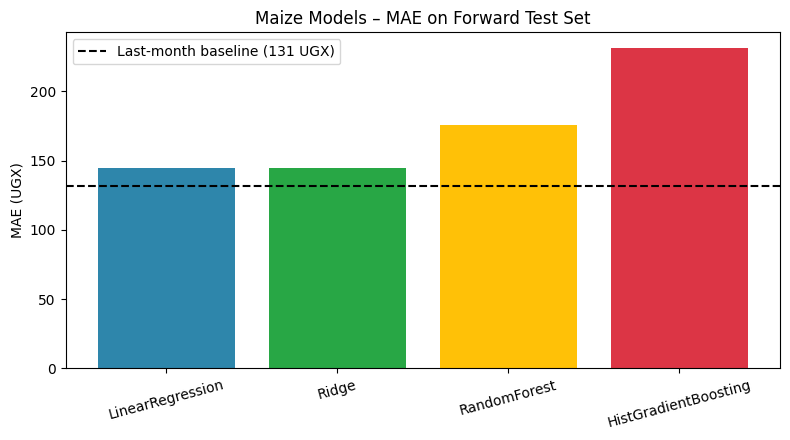

In [4]:
res_df = pd.DataFrame(results)
plt.figure(figsize=(8, 4.5))
colors = ['#2E86AB', '#28A745', '#FFC107', '#DC3545']
plt.bar(res_df['model'], res_df['MAE'], color=colors)
plt.axhline(baseline_mae, color='black', ls='--', label=f'Last-month baseline ({baseline_mae:.0f} UGX)')
plt.title('Maize Models – MAE on Forward Test Set')
plt.ylabel('MAE (UGX)'); plt.xticks(rotation=15); plt.legend()
plt.tight_layout()
plt.savefig('../figures/05_maize_mae_comparison.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 5.5 – Graph 2: Maize predicted vs actual


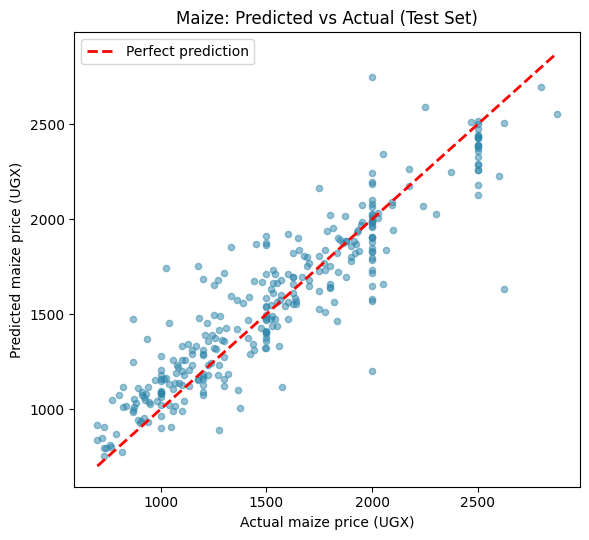

In [5]:
pred_m = best_pipe.predict(X_test)
plt.figure(figsize=(6, 5.5))
plt.scatter(y_test, pred_m, alpha=0.5, c='#2E86AB', s=20)
lims = [min(y_test.min(), pred_m.min()), max(y_test.max(), pred_m.max())]
plt.plot(lims, lims, 'r--', lw=2, label='Perfect prediction')
plt.xlabel('Actual maize price (UGX)'); plt.ylabel('Predicted maize price (UGX)')
plt.title('Maize: Predicted vs Actual (Test Set)')
plt.legend(); plt.tight_layout()
plt.savefig('../figures/05_maize_pred_vs_actual.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 5.6 – Graph 3: Maize residuals over time


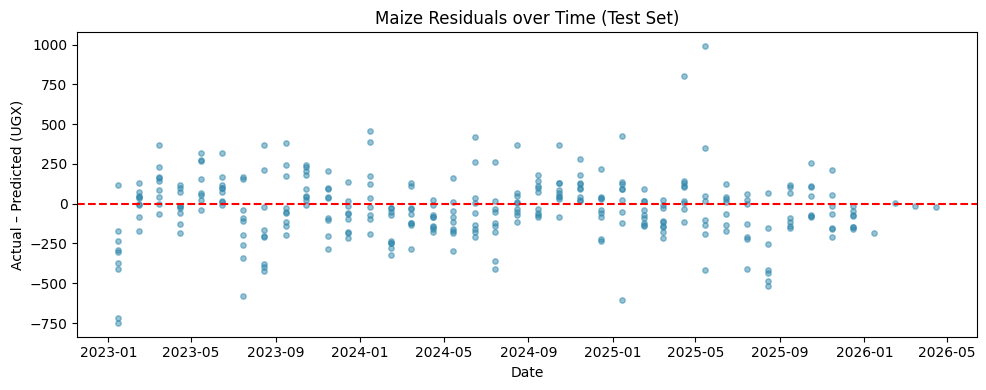

In [6]:
residuals = y_test.values - pred_m
plt.figure(figsize=(10, 4))
plt.scatter(test_m['date'], residuals, alpha=0.5, c='#2E86AB', s=15)
plt.axhline(0, color='red', ls='--')
plt.title('Maize Residuals over Time (Test Set)')
plt.xlabel('Date'); plt.ylabel('Actual – Predicted (UGX)')
plt.tight_layout()
plt.savefig('../figures/05_maize_residuals.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 5.7 – Repeat for beans


In [7]:
beans_feats = [
    'beans_price_lag1', 'beans_price_lag2', 'beans_price_lag3',
    'beans_price_lag6', 'beans_price_lag12', 'beans_price_roll3',
    'maize_price_lag1', 'month_sin', 'month_cos',
    'latitude', 'longitude', 'year', 'month'
]
preprocessor_b = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), beans_feats),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                      ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), ['market'])
])
X_train_b = train_b[beans_feats + ['market']]
y_train_b = train_b['beans_price']
X_test_b  = test_b[beans_feats + ['market']]
y_test_b  = test_b['beans_price']

baseline_pred_b = X_test_b['beans_price_lag1']
baseline_mae_b  = mean_absolute_error(y_test_b, baseline_pred_b)
print(f"BEANS BASELINE (last month) MAE = {baseline_mae_b:.1f} UGX\n")

results_b = []
best_mae_b, best_name_b, best_pipe_b = 999999, None, None
for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor_b), ('model', model)])
    pipe.fit(X_train_b, y_train_b)
    pred = pipe.predict(X_test_b)
    mae  = mean_absolute_error(y_test_b, pred)
    rmse = np.sqrt(mean_squared_error(y_test_b, pred))
    r2   = r2_score(y_test_b, pred)
    results_b.append({'model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2})
    print(f"{name:22s}  MAE = {mae:6.1f}   RMSE = {rmse:6.1f}   R2 = {r2:.3f}")
    if mae < best_mae_b:
        best_mae_b, best_name_b, best_pipe_b = mae, name, pipe
print(f"\nBest beans model: {best_name_b} with MAE {best_mae_b:.1f} UGX")


BEANS BASELINE (last month) MAE = 288.2 UGX

LinearRegression        MAE =  324.4   RMSE =  437.4   R2 = 0.706
Ridge                   MAE =  324.1   RMSE =  436.9   R2 = 0.707
RandomForest            MAE =  364.3   RMSE =  493.1   R2 = 0.627
HistGradientBoosting    MAE =  397.5   RMSE =  521.5   R2 = 0.583

Best beans model: Ridge with MAE 324.1 UGX


## Step 5.8 – Graph 4: Beans MAE comparison


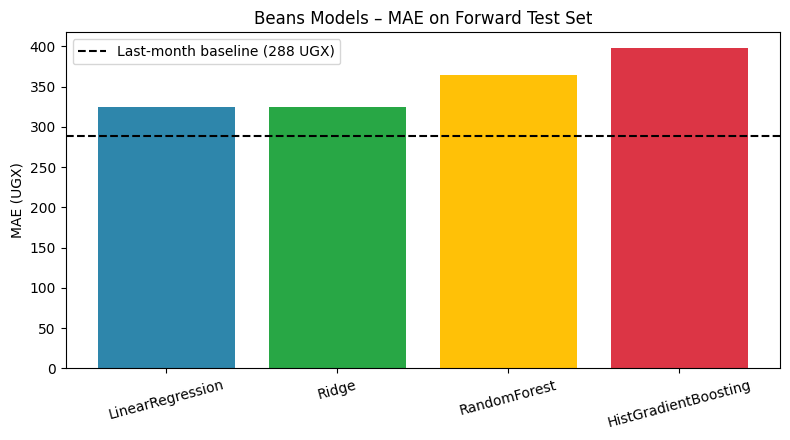

In [8]:
res_b_df = pd.DataFrame(results_b)
plt.figure(figsize=(8, 4.5))
plt.bar(res_b_df['model'], res_b_df['MAE'], color=colors)
plt.axhline(baseline_mae_b, color='black', ls='--', label=f'Last-month baseline ({baseline_mae_b:.0f} UGX)')
plt.title('Beans Models – MAE on Forward Test Set')
plt.ylabel('MAE (UGX)'); plt.xticks(rotation=15); plt.legend()
plt.tight_layout()
plt.savefig('../figures/05_beans_mae_comparison.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 5.9 – Graph 5: Beans predicted vs actual


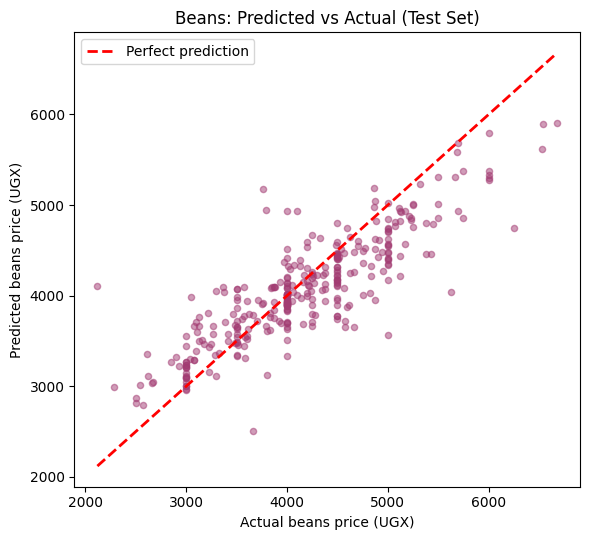

In [9]:
pred_b = best_pipe_b.predict(X_test_b)
plt.figure(figsize=(6, 5.5))
plt.scatter(y_test_b, pred_b, alpha=0.5, c='#A23B72', s=20)
lims = [min(y_test_b.min(), pred_b.min()), max(y_test_b.max(), pred_b.max())]
plt.plot(lims, lims, 'r--', lw=2, label='Perfect prediction')
plt.xlabel('Actual beans price (UGX)'); plt.ylabel('Predicted beans price (UGX)')
plt.title('Beans: Predicted vs Actual (Test Set)')
plt.legend(); plt.tight_layout()
plt.savefig('../figures/05_beans_pred_vs_actual.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 5.10 – Save comparison tables and best pipelines


In [10]:
pd.DataFrame(results).to_csv('../predictions/maize_model_comparison.csv', index=False)
pd.DataFrame(results_b).to_csv('../predictions/beans_model_comparison.csv', index=False)
joblib.dump({'pipeline': best_pipe, 'features': maize_feats + ['market']}, '../models/best_maize_pipeline.joblib')
joblib.dump({'pipeline': best_pipe_b, 'features': beans_feats + ['market']}, '../models/best_beans_pipeline.joblib')

test_m = test_m.copy(); test_m['pred_maize'] = pred_m
test_m[['date','market','maize_price','pred_maize']].to_csv('../predictions/test_predictions_maize.csv', index=False)
test_b = test_b.copy(); test_b['pred_beans'] = pred_b
test_b[['date','market','beans_price','pred_beans']].to_csv('../predictions/test_predictions_beans.csv', index=False)
print("Models, comparisons and test predictions saved.")


Models, comparisons and test predictions saved.
